In [1]:
from backtester.data import load_prices
from backtester.strategy import sma_crossover

spy = load_prices('SPY', '2015-01-01', '2026-01-01')
signals = sma_crossover(spy['Adj Close'])

Loaded SPY from cache: SPY_2015-01-01_2026-01-01.csv


In [6]:
import numpy as np
import pandas as pd

In [2]:
sma_crossover(spy["Adj Close"].iloc[:49])

ValueError: Invalid input: The length of the price series must be greater than or equal to the slow SMA period.

In [ ]:
sma_crossover(spy["Adj Close"].iloc[:50])

Date
2010-01-04    0
2010-01-05    0
2010-01-06    0
2010-01-07    0
2010-01-08    0
2010-01-11    0
2010-01-12    0
2010-01-13    0
2010-01-14    0
2010-01-15    0
2010-01-19    0
2010-01-20    0
2010-01-21    0
2010-01-22    0
2010-01-25    0
2010-01-26    0
2010-01-27    0
2010-01-28    0
2010-01-29    0
2010-02-01    0
2010-02-02    0
2010-02-03    0
2010-02-04    0
2010-02-05    0
2010-02-08    0
2010-02-09    0
2010-02-10    0
2010-02-11    0
2010-02-12    0
2010-02-16    0
2010-02-17    0
2010-02-18    0
2010-02-19    0
2010-02-22    0
2010-02-23    0
2010-02-24    0
2010-02-25    0
2010-02-26    0
2010-03-01    0
2010-03-02    0
2010-03-03    0
2010-03-04    0
2010-03-05    0
2010-03-08    0
2010-03-09    0
2010-03-10    0
2010-03-11    0
2010-03-12    0
2010-03-15    0
2010-03-16    1
dtype: int64

In [ ]:
sma_crossover(spy["Adj Close"], fast=0, slow=50)

ValueError: Invalid input: SMA periods (0, 50) must be positive integers.

In [5]:
signals.loc["2020-02-28":"2020-03-05"]

Date
2020-02-28    1
2020-03-02    1
2020-03-03    0
2020-03-04    0
2020-03-05    0
dtype: int64

In [6]:
signals.loc["2020-04-27":"2020-05-04"]

Date
2020-04-27    0
2020-04-28    0
2020-04-29    0
2020-04-30    1
2020-05-01    1
2020-05-04    1
dtype: int64

In [8]:
signals.value_counts()

1    1975
0     793
Name: count, dtype: int64

In [3]:
sma_crossover(spy["Adj Close"], fast=20, slow=0)

ValueError: Invalid input: The fast SMA period (20) must be less than the slow SMA period (0).

In [7]:
a = pd.Series([np.nan, 5.0])
b = pd.Series([1.0, 1.0])
a > b

0    False
1     True
dtype: bool

In [5]:
x = pd.Series([1, 1, 0, 0, 1])
x.shift(1)

0    NaN
1    1.0
2    1.0
3    0.0
4    0.0
dtype: float64

In [15]:
position = signals.shift(1).fillna(0).astype(int)
position

Date
2015-01-02    0
2015-01-05    0
2015-01-06    0
2015-01-07    0
2015-01-08    0
             ..
2025-12-24    1
2025-12-26    1
2025-12-29    1
2025-12-30    1
2025-12-31    1
Length: 2766, dtype: int64

In [13]:
check = pd.DataFrame({"signal": signals, "position": position})
check.loc["2020-02-28":"2020-03-05"]

,signal,position
Date,,
2020-02-28,1,1.0
2020-03-02,1,1.0
2020-03-03,0,1.0
2020-03-04,0,0.0
2020-03-05,0,0.0


In [14]:
check.loc["2020-04-27":"2020-05-04"]

,signal,position
Date,,
2020-04-27,0,0.0
2020-04-28,0,0.0
2020-04-29,0,0.0
2020-04-30,1,0.0
2020-05-01,1,1.0
2020-05-04,1,1.0


In [20]:
changes = signals != signals.shift(1)
signals[changes].iloc[1:]


Date
2015-03-16    1
2015-04-20    0
2015-04-24    1
2015-06-25    0
2015-08-03    1
2015-08-19    0
2015-10-22    1
2015-12-22    0
2016-03-09    1
2016-05-26    0
2016-05-27    1
2016-09-19    0
2016-11-21    1
2017-04-19    0
2017-05-03    1
2017-09-07    0
2017-09-08    1
2018-02-23    0
2018-05-15    1
2018-10-18    0
2019-01-31    1
2019-05-29    0
2019-06-27    1
2019-08-16    0
2019-09-18    1
2020-03-03    0
2020-04-30    1
2020-10-01    0
2020-10-20    1
2021-10-01    0
2021-10-28    1
2022-01-25    0
2022-04-01    1
2022-05-02    0
2022-08-01    1
2022-09-16    0
2022-11-11    1
2023-01-03    0
2023-01-27    1
2023-03-14    0
2023-04-13    1
2023-08-28    0
2023-11-20    1
2024-04-26    0
2024-05-20    1
2024-08-09    0
2024-09-03    1
2025-01-14    0
2025-02-04    1
2025-03-07    0
2025-05-14    1
dtype: int64

In [21]:
len(changes)

2766

In [22]:
changes.head(10)

Date
2015-01-02     True
2015-01-05    False
2015-01-06    False
2015-01-07    False
2015-01-08    False
2015-01-09    False
2015-01-12    False
2015-01-13    False
2015-01-14    False
2015-01-15    False
dtype: bool

In [23]:
spy["SMA_20"] = spy["Adj Close"].rolling(20).mean()
spy["SMA_50"] = spy["Adj Close"].rolling(50).mean()

In [31]:
spy.loc["2016-09-15":"2016-09-21", ["Adj Close", "SMA_20", "SMA_50"]]

,Adj Close,SMA_20,SMA_50
Date,,,
2016-09-15,182.924164,184.601008,184.201049
2016-09-16,182.216934,184.413553,184.284622
2016-09-19,182.251190,184.241403,184.315857
2016-09-20,182.259720,184.070104,184.334518
2016-09-21,184.309296,183.982594,184.367829


In [32]:
spy.loc["2017-04-17":"2017-04-21", ["Adj Close", "SMA_20", "SMA_50"]]

,Adj Close,SMA_20,SMA_50
Date,,,
2017-04-17,202.379028,202.617165,202.372350
2017-04-18,201.775116,202.492062,202.467658
2017-04-19,201.404114,202.479552,202.562591
2017-04-20,203.043381,202.525279,202.690136
2017-04-21,202.396286,202.549435,202.799586


In [35]:
spy.loc["2017-05-01":"2017-05-05", ["Adj Close", "SMA_20", "SMA_50"]]

,Adj Close,SMA_20,SMA_50
Date,,,
2017-05-01,205.925018,203.373810,203.443495
2017-05-02,206.002655,203.522208,203.524567
2017-05-03,205.752457,203.651622,203.576581
2017-05-04,205.994064,203.823315,203.637035
2017-05-05,206.805054,204.007088,203.710959


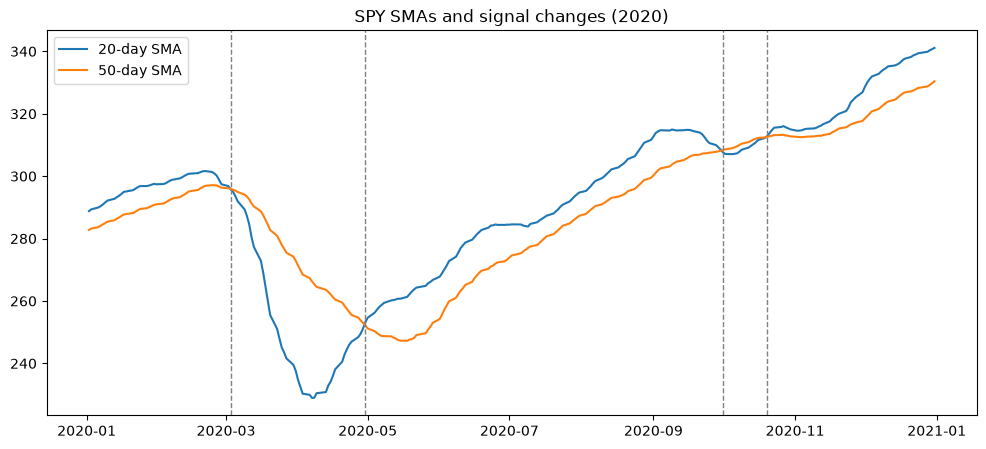

In [37]:
import matplotlib.pyplot as plt

year = "2020"
view = spy.loc[year]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(view.index, view["SMA_20"], label="20-day SMA")
ax.plot(view.index, view["SMA_50"], label="50-day SMA")

for date in signals[changes].iloc[1:].loc[year].index:
    ax.axvline(date, color="grey", linestyle="--", linewidth=1)

ax.set_title(f"SPY SMAs and signal changes ({year})")
ax.legend()
plt.show()

## Crossover checks

Each change in `signals` was checked against the SMA values the day before and on the day.

| Date | Change | Day before | On the day | Matches? |
|---|---|---|---|---|
| 3 Mar 2020 | 1 to 0 | SMA_20 296.84 > SMA_50 296.14 | SMA_20 295.75 < SMA_50 295.82 | Yes |
| 30 Apr 2020 | 0 to 1 | SMA_20 251.20 < SMA_50 252.98 | SMA_20 253.23 > SMA_50 252.15 | Yes |
| 03 May 2017 | 0 to 1 | SMA_20 203.522 < SMA_50 203.524 | SMA_20 203.65 > SMA_50 203.57 | Yes |
| 19 Apr 2017 | 1 to 0 | SMA_20 202.49 > SMA_50 202.46 | SMA_20 202.47 < SMA_50 202.56 | Yes |
| 19 Sep 2016 | 1 to 0 | SMA_20 184.41 > SMA_50 184.28 | SMA_20 184.24 < SMA_50 184.31 | Yes |